# Member 1: Data Collection and Data Quality

**Course:** Time Series Forecasting  
**Group:** C1 
**Target Stock:** Microsoft Corporation (MSFT)  
**Data Download Date:** 17 November 2026

## 1. Introduction

This notebook documents the collection, inspection, and preparation
of historical stock market data for Microsoft Corporation (MSFT).

The dataset includes historical OHLCV stock data and seven market
predictor series. The purpose is to assess data completeness,
consistency, and reliability before conducting time series analysis
and forecasting.

In [3]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tslab import config
from tslab.data import load_market_data, data_quality_report

%matplotlib inline

plt.rcParams["figure.figsize"] = (12, 5)

print("Python version:", sys.version.split()[0])
print("Working directory:", os.getcwd())
print("Target stock:", config.TARGET_TICKER)

Python version: 3.11.16
Working directory: C:\Users\sigei\OneDrive\Desktop\BI Projects\TimeSeriesForecasting-C1\TimeSeriesForecastingandNeuralNetworks-1
Target stock: MSFT


In [4]:

data = load_market_data()
data.head()

Loaded 2981 trading days of MSFT, 2015-01-02 to 2026-11-09, with 7 predictor series.


,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD
Date,,,,,,,,,,,,
2015-01-02,39.522487,40.166230,39.420844,39.607189,27913900,2058.199951,18.041676,17.790001,2.123,91.080002,56.419998,1186.000000
2015-01-05,39.276844,39.581776,39.175202,39.242966,39673900,2020.579956,17.766277,19.920000,2.039,91.379997,53.110001,1203.900024
2015-01-06,39.285321,39.598722,38.573814,38.666988,36447900,2002.609985,17.552057,21.120001,1.963,91.500000,51.099998,1219.300049
2015-01-07,38.946499,39.353073,38.531455,39.158257,29114100,2025.900024,17.700701,19.309999,1.954,91.889999,51.150002,1210.599976
2015-01-08,39.598720,40.445751,39.573310,40.310226,29645200,2062.139893,18.089766,17.010000,2.016,92.370003,50.959999,1208.400024


In [5]:
# Check the quality of the loaded market data
quality = data_quality_report(data)

quality

rows                               2981
first_date                   2015-01-02
last_date                    2026-11-09
duplicate_dates                       0
missing_values                        0
non_positive_prices                   0
days_with_zero_volume                 0
high_below_low                        0
longest_gap_in_days                   4
days_with_move_over_10pct             6
dtype: object


## 2. Data Quality Assessment

The dataset contains 2,981 trading observations covering the period from 2 January 2015 to 9 November 2026. The quality assessment identified no duplicate dates, missing values, non-positive prices, zero-volume trading days, or instances where the recorded high price was below the low price.

The longest gap between observations was four days, which is consistent with possible weekends or market holidays. However, six observations recorded price movements exceeding 10%. These unusual movements require further investigation but should not automatically be treated as errors or removed.

Overall, the dataset demonstrates good completeness and consistency and is suitable for further time series analysis.


In [6]:
# Calculate daily percentage changes in Microsoft's closing price
daily_returns = data["Close"].pct_change() * 100

# Identify movements greater than 10% in either direction
unusual_movements = daily_returns[daily_returns.abs() > 10]

# Display the dates, percentage changes and OHLCV information
unusual_data = data.loc[unusual_movements.index, 
                        ["Open", "High", "Low", "Close", "Volume"]].copy()

unusual_data["Percentage_Change"] = unusual_movements

unusual_data

,Open,High,Low,Close,Volume,Percentage_Change
Date,,,,,,
2015-04-24,38.950692,41.066279,38.942163,40.835953,130933700,10.452278
2015-10-23,45.201068,46.730818,45.157855,45.693699,135227100,10.077028
2020-03-13,139.545691,153.178599,133.140776,150.264694,92727400,14.216862
2020-03-16,132.450171,141.295957,127.719808,128.117157,87905900,-14.739016
2025-04-09,349.437886,388.667365,349.002989,385.959137,50199700,10.133674
2026-07-30,437.077201,457.828146,431.627468,450.252411,110160700,15.506739


In [7]:
# Validate OHLC price relationships and trading volume
validation = pd.DataFrame(index=unusual_data.index)

validation["High_valid"] = unusual_data["High"] >= unusual_data["Low"]
validation["Low_valid"] = (
    (unusual_data["Low"] <= unusual_data["Open"]) &
    (unusual_data["Low"] <= unusual_data["Close"])
)
validation["High_valid"] = (
    validation["High_valid"] &
    (unusual_data["High"] >= unusual_data["Open"]) &
    (unusual_data["High"] >= unusual_data["Close"])
)
validation["Volume_valid"] = unusual_data["Volume"] > 0

validation["All_checks_passed"] = validation.all(axis=1)

validation

,High_valid,Low_valid,Volume_valid,All_checks_passed
Date,,,,
2015-04-24,True,True,True,True
2015-10-23,True,True,True,True
2020-03-13,True,True,True,True
2020-03-16,True,True,True,True
2025-04-09,True,True,True,True
2026-07-30,True,True,True,True



## 3. Investigation of Unusual Price Movements

The data quality report identified six trading days with closing price movements exceeding 10%. These occurred on 24 April 2015, 23 October 2015, 13 March 2020, 16 March 2020, 9 April 2025, and 30 July 2026.

Further validation confirmed that all six observations had consistent opening, highest, lowest, and closing prices, as well as positive trading volumes. The large movements were therefore not accompanied by obvious OHLCV data inconsistencies.

The movements recorded in March 2020 occurred during the COVID-19 market volatility. The other unusual movements require additional historical context before their causes can be established.

The observations have been retained because unusually large market movements can represent genuine market behaviour. Removing them without sufficient evidence could distort the historical data and affect forecasting results.


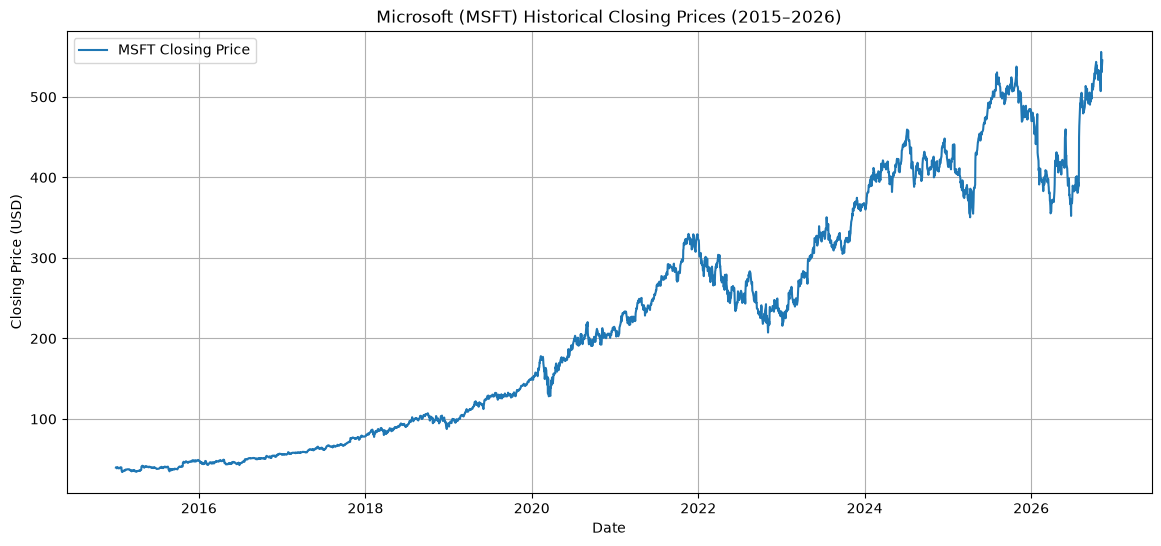

In [8]:
# Plot Microsoft's historical closing prices
plt.figure(figsize=(14, 6))

plt.plot(data.index, data["Close"], label="MSFT Closing Price")

plt.title("Microsoft (MSFT) Historical Closing Prices (2015–2026)")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)

plt.show()


## 4. Historical Closing Price Visualisation

The line chart illustrates Microsoft's historical closing prices from 2015 to 2026. Overall, the stock demonstrates a long-term upward trend, although the price experienced several periods of significant volatility and temporary declines.

The fluctuations became more noticeable from 2020 onwards. Despite these declines, the stock generally recovered over time and reached higher price levels towards the end of the observation period.

This visualisation provides an overview of the historical price behaviour and highlights the importance of considering market volatility when developing forecasting models.


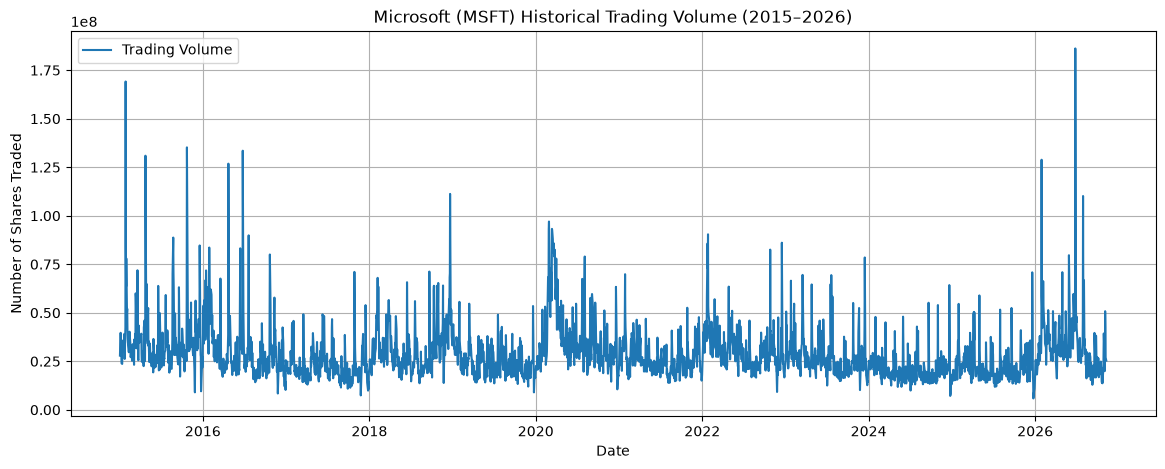

In [9]:
# Plot Microsoft's historical trading volume
plt.figure(figsize=(14, 5))

plt.plot(data.index, data["Volume"], label="Trading Volume")

plt.title("Microsoft (MSFT) Historical Trading Volume (2015–2026)")
plt.xlabel("Date")
plt.ylabel("Number of Shares Traded")
plt.legend()
plt.grid(True)

plt.show()


## 5. Historical Trading Volume Analysis

The trading volume chart illustrates the daily number of Microsoft shares traded between 2015 and 2026. Trading activity fluctuated throughout the period, with several noticeable spikes indicating days of unusually high market activity.

Significant volume spikes can be observed around 2015–2016, 2020 and 2026. These periods may be worth examining alongside changes in closing prices to understand the relationship between trading activity and market volatility.

Trading volume is an important variable in financial time series analysis because it provides additional information about market activity and investor participation.


In [11]:
# Select the February–April 2020 trading period
period_2020 = data.loc["2020-02-01":"2020-04-30"]

# Display the selected observations
period_2020[["Open", "High", "Low", "Close", "Volume"]].head()

,Open,High,Low,Close,Volume
Date,,,,,
2020-02-03,160.799945,164.639979,160.771641,164.526764,30107000
2020-02-04,167.130801,170.433035,166.347698,169.942413,36433300
2020-02-05,173.631521,173.791913,168.329079,169.734879,39186300
2020-02-06,170.744403,173.433371,169.885818,173.254105,27751400
2020-02-07,172.518206,175.141123,172.169103,173.499435,33529100


In [13]:
%pip install mplfinance

Note: you may need to restart the kernel to use updated packages.


findfont: Failed to find font weight semibold, now using 700.


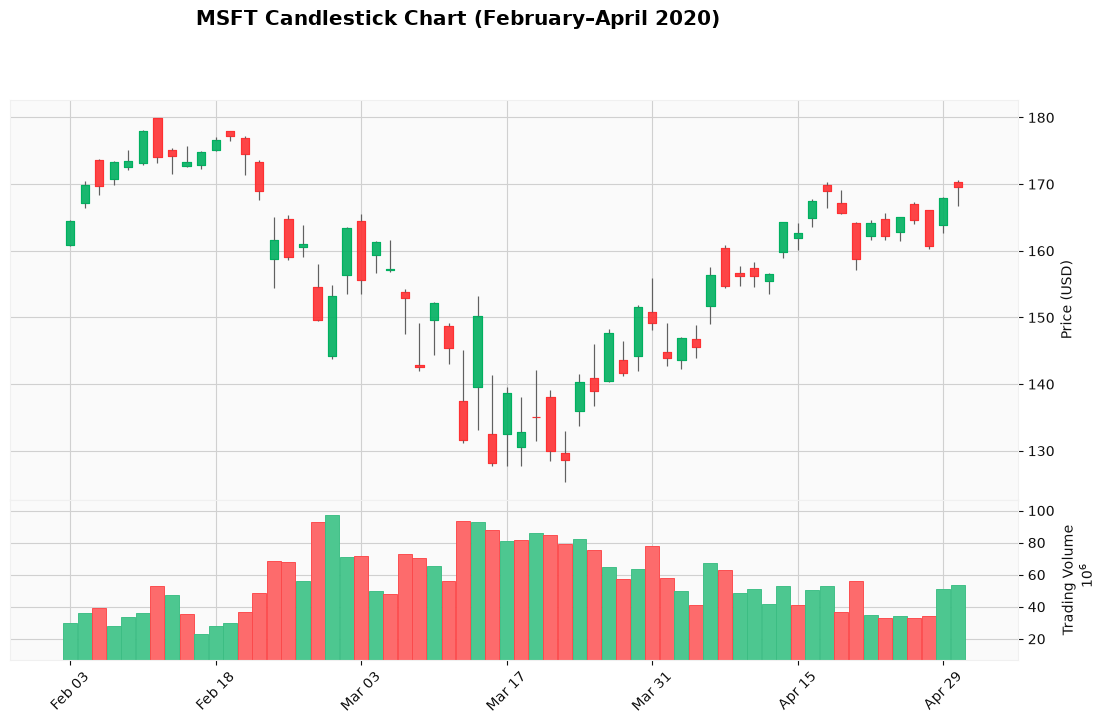

In [14]:
import mplfinance as mpf

mpf.plot(
    period_2020,
    type="candle",
    volume=True,
    style="yahoo",
    title="MSFT Candlestick Chart (February–April 2020)",
    ylabel="Price (USD)",
    ylabel_lower="Trading Volume",
    figsize=(14, 8)
)


## 6. Candlestick Chart Analysis

The candlestick chart illustrates Microsoft's daily price movements between February and April 2020. Each candlestick represents the opening, highest, lowest, and closing prices for a trading day.

The chart shows considerable price volatility during this period, with noticeable upward and downward movements. The accompanying trading volume bars provide additional information about market activity.

The period is particularly important because it coincided with the COVID-19 pandemic, which contributed to uncertainty and volatility in financial markets. Observing price movements alongside trading volume helps identify periods of increased market activity and understand how trading behaviour changes during sharp price movements.


In [15]:
# Calculate daily percentage price changes
period_2020 = period_2020.copy()

period_2020["Daily_Return_%"] = (
    period_2020["Close"].pct_change() * 100
)

# Identify the five largest daily price declines
largest_declines = period_2020.nsmallest(
    5, "Daily_Return_%"
)

largest_declines[
    ["Open", "High", "Low", "Close", "Volume", "Daily_Return_%"]
]

,Open,High,Low,Close,Volume,Daily_Return_%
Date,,,,,,
2020-03-16,132.450171,141.295957,127.719808,128.117157,87905900,-14.739016
2020-03-12,137.464366,145.193778,131.106756,131.560867,93226400,-9.483820
2020-02-27,154.512592,158.022514,149.460553,149.649765,93174900,-7.045924
2020-03-09,142.857010,149.243002,141.910937,142.497498,70419300,-6.777229
2020-03-03,164.427436,165.562720,153.509749,155.638412,71677000,-4.791952



## 7. Relationship Between Price Declines and Trading Volume

The analysis identified five of the largest daily price declines between February and April 2020. The largest decline occurred on 16 March 2020, when Microsoft's closing price fell by approximately 14.74%, accompanied by a trading volume of 87.9 million shares.

Other significant declines occurred on 12 March and 27 February 2020, with trading volumes exceeding 93 million shares.

These observations suggest that substantial price declines can coincide with high trading activity. However, high trading volume does not always correspond to a price decline, and further analysis would be required to establish a consistent relationship between trading volume and price movements.


In [16]:
# Calculate daily logarithmic returns
data["Log_Return"] = np.log(data["Close"]).diff()

# Display the first five calculated returns
data[["Close", "Log_Return"]].head()

,Close,Log_Return
Date,,
2015-01-02,39.607189,NaN
2015-01-05,39.242966,-0.009238
2015-01-06,38.666988,-0.014786
2015-01-07,39.158257,0.012625
2015-01-08,40.310226,0.028994



## 8. Calculation of Daily Log Returns

Daily logarithmic returns were calculated using the natural logarithm of consecutive closing prices. This measures the relative change in Microsoft's stock price between trading days.

The first observation contains a missing value (NaN) because there is no preceding closing price available for calculating the return. Negative values indicate a decrease in closing price, while positive values indicate an increase.

Log returns are useful in financial time series analysis because they provide a consistent way to measure price changes and are commonly used as forecasting targets.


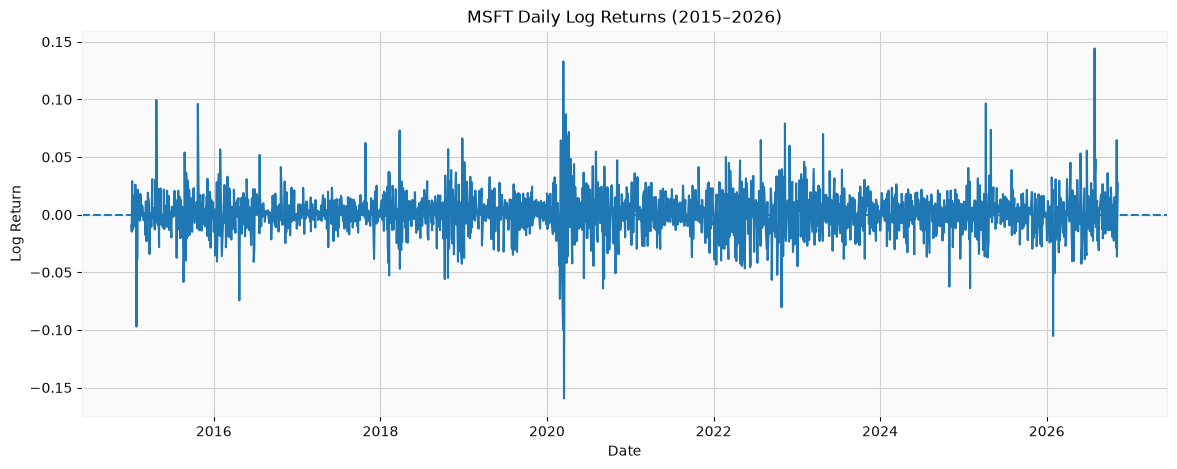

In [17]:
plt.figure(figsize=(14, 5))

plt.plot(data.index, data["Log_Return"])

plt.title("MSFT Daily Log Returns (2015–2026)")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.axhline(y=0, linestyle="--")
plt.grid(True)

plt.show()


## 9. Visualisation of Daily Log Returns

The daily log returns chart shows the percentage-like changes in Microsoft's stock price over the observation period. The returns fluctuate around zero, with positive values representing price increases and negative values representing price decreases.

Most daily movements are relatively small, although several large positive and negative spikes indicate periods of increased market volatility.

Unlike the historical closing price chart, which shows the long-term price trend, the log returns chart highlights daily price fluctuations and changes in market risk. This makes log returns useful for financial forecasting and volatility analysis.


In [18]:
# Generate descriptive statistics for daily log returns
data["Log_Return"].describe()

count    2980.000000
mean        0.000880
std         0.017358
min        -0.159453
25%        -0.007111
50%         0.000908
75%         0.009614
max         0.144159
Name: Log_Return, dtype: float64


## 10. Descriptive Statistics of Daily Log Returns

The descriptive statistics provide an overview of Microsoft's daily log returns across the observation period.

The mean daily log return is 0.000880, indicating a small positive average return. The standard deviation is 0.017358, showing that daily returns fluctuate around their average.

The minimum return of -0.159453 and maximum return of 0.144159 demonstrate that the stock experienced substantial negative and positive daily movements. The median return of 0.000908 is slightly positive.

Overall, the statistics indicate that Microsoft's stock experienced both positive and negative daily returns, with occasional extreme movements. These findings highlight the importance of considering volatility when developing forecasting models.


In [19]:
# Calculate correlations between daily log returns and market predictors
predictors = ["SP500", "TECH", "VIX", "US10Y", "USD", "BRENT", "GOLD"]

correlations = data[["Log_Return"] + predictors].corr()

# Display correlations with MSFT log returns
correlations["Log_Return"].sort_values(ascending=False)

Log_Return    1.000000
TECH         -0.001134
SP500        -0.002483
US10Y        -0.009588
GOLD         -0.012530
USD          -0.015080
BRENT        -0.016971
VIX          -0.115529
Name: Log_Return, dtype: float64


## 11. Correlation Analysis Between MSFT Returns and Market Predictors

The correlation analysis examined the relationship between Microsoft's daily log returns and seven market predictor variables.

The results show that most predictors have correlations very close to zero, indicating very weak linear relationships with MSFT daily log returns. The VIX has the strongest negative correlation at -0.115529, suggesting a weak inverse relationship.

The S&P 500 and technology fund (TECH) also have correlations close to zero in this analysis.

However, correlation alone does not establish predictive value. The timing of predictor observations is important because information available today should be used to forecast future stock returns rather than relying only on same-day relationships.



## 12. Why Same-Day S&P 500 Correlation Is Not Enough

The correlation between the S&P 500 and MSFT returns on the same trading day does not necessarily demonstrate predictive value. This is because both variables may respond to the same market information during that day.

For forecasting purposes, the timing of the information is important. The S&P 500 value available today should be used to predict Microsoft's return on the next trading day. Therefore, lagged predictor variables should be considered when evaluating their forecasting usefulness.

This helps prevent look-ahead bias and ensures that the forecasting model only uses information that would have been available at the time of prediction.



## 13. Exercise 1: Data Quality

The data quality result that would concern me most if it were not zero is missing_values. Missing values can affect calculations, reduce the number of usable observations and cause forecasting models to produce inaccurate results. They should therefore be investigated and handled appropriately before modelling.


In [21]:
import numpy as np

# Assume the initial stock price is 100
initial_price = 100

# Stock rises by 50%
price_after_increase = initial_price * 1.50

# Stock then falls by 50%
final_price = price_after_increase * 0.50

# Calculate total simple return
simple_return = (final_price - initial_price) / initial_price

# Calculate total log return
log_return = np.log(final_price / initial_price)

print("Initial price:", initial_price)
print("Price after 50% increase:", price_after_increase)
print("Final price after 50% decrease:", final_price)
print("Total simple return:", simple_return)
print("Total log return:", log_return)

Initial price: 100
Price after 50% increase: 150.0
Final price after 50% decrease: 75.0
Total simple return: -0.25
Total log return: -0.2876820724517809


### Exercise 4: Simple Returns and Log Returns

A stock initially priced at 100 increases by 50% to 150. It then decreases by 50%, resulting in a final price of 75.

The total simple return is -25%, while the cumulative log return is approximately -0.2877.

This demonstrates that a 50% increase followed by a 50% decrease does not result in a zero return. The percentage decrease is calculated using the increased price, resulting in an overall loss of 25%.

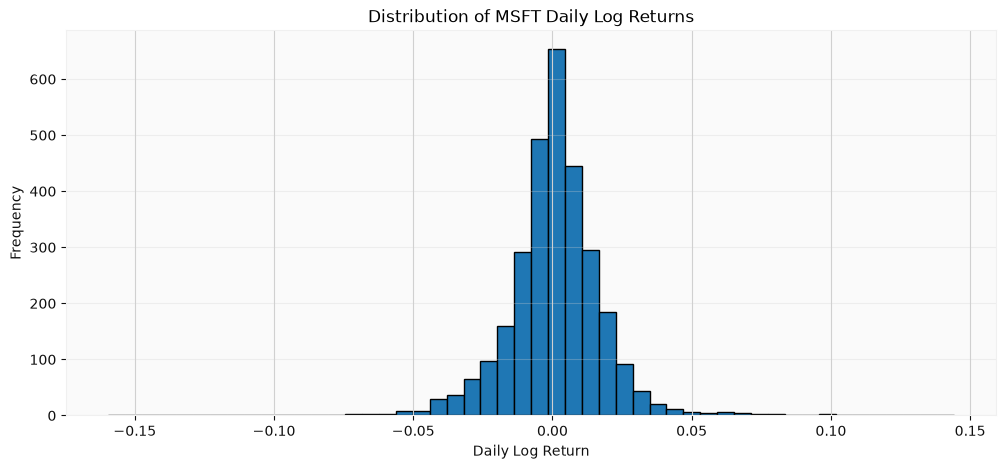

In [22]:
plt.figure(figsize=(12, 5))

plt.hist(data["Log_Return"].dropna(), bins=50, edgecolor="black")

plt.title("Distribution of MSFT Daily Log Returns")
plt.xlabel("Daily Log Return")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [23]:
# Calculate daily percentage changes for market predictors
predictor_returns = data[predictors].pct_change()

# Calculate daily changes in the US 10-year yield
predictor_returns["US10Y"] = data["US10Y"].diff()

# Combine MSFT log returns with predictor changes
correlation_data = pd.concat(
    [data["Log_Return"], predictor_returns],
    axis=1
)

# Remove rows with missing values
correlation_data = correlation_data.dropna()

print("Correlation dataset shape:", correlation_data.shape)

correlation_data.head()

Correlation dataset shape: (2980, 8)


,Log_Return,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD
Date,,,,,,,,
2015-01-05,-0.009238,-0.018278,-0.015265,0.119730,-0.084,0.003294,-0.058667,0.015093
2015-01-06,-0.014786,-0.008893,-0.012058,0.060241,-0.076,0.001313,-0.037846,0.012792
2015-01-07,0.012625,0.011630,0.008469,-0.085701,-0.009,0.004262,0.000979,-0.007135
2015-01-08,0.028994,0.017888,0.021980,-0.119109,0.062,0.005224,-0.003715,-0.001817
2015-01-09,-0.008441,-0.008404,-0.003141,0.031746,-0.045,-0.004655,-0.016680,0.006289


In [24]:
# Calculate correlations between MSFT returns and predictor changes
corrected_correlations = correlation_data.corr()

# Display correlations with MSFT log returns
msft_correlations = (
    corrected_correlations["Log_Return"]
    .sort_values(ascending=False)
)

msft_correlations

Log_Return    1.000000
TECH          0.800841
SP500         0.757201
BRENT         0.119576
US10Y         0.087618
GOLD          0.024132
USD          -0.037937
VIX          -0.547917
Name: Log_Return, dtype: float64

### Corrected Correlation Analysis

The correlation analysis compares MSFT daily log returns with the daily percentage changes of the market predictors and daily changes in the US 10-year yield.

The results show a strong positive correlation between MSFT returns and TECH (0.8008), followed by SP500 (0.7572). This suggests that Microsoft stock movements are closely associated with technology-sector and broader market movements.

VIX has a negative correlation of -0.5479, suggesting that MSFT returns tend to decrease when market volatility increases. BRENT (0.1196), US10Y (0.0876), GOLD (0.0241) and USD (-0.0379) have relatively weak linear relationships with MSFT returns.

However, correlation does not establish causation or prove predictive ability. Further analysis using lagged predictors and time-series validation is necessary to determine whether these variables can help forecast future MSFT returns.

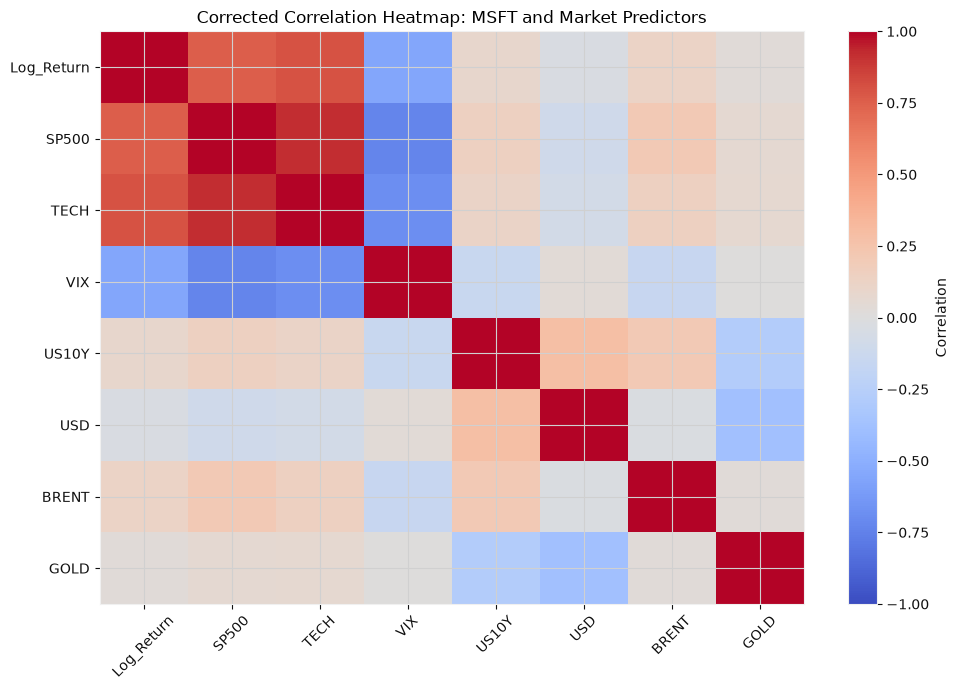

In [25]:
plt.figure(figsize=(10, 7))

plt.imshow(corrected_correlations, cmap="coolwarm", aspect="auto",
           vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(corrected_correlations.columns)),
    corrected_correlations.columns,
    rotation=45
)

plt.yticks(
    range(len(corrected_correlations.index)),
    corrected_correlations.index
)

plt.title("Corrected Correlation Heatmap: MSFT and Market Predictors")
plt.tight_layout()
plt.show()

In [26]:
# Shift predictor changes by one trading day
lagged_predictors = predictor_returns.shift(1)

# Combine yesterday's predictor changes with today's MSFT returns
lagged_data = pd.concat(
    [data["Log_Return"], lagged_predictors],
    axis=1
).dropna()

# Calculate correlations
lagged_correlations = lagged_data.corr()["Log_Return"].sort_values(
    ascending=False
)

lagged_correlations

Log_Return    1.000000
VIX           0.053036
GOLD          0.018533
USD          -0.016973
BRENT        -0.035269
US10Y        -0.046998
TECH         -0.099766
SP500        -0.135284
Name: Log_Return, dtype: float64

### Lagged Predictor Correlation Analysis

The lagged correlation analysis examines whether previous-day movements in market predictors are associated with current MSFT daily log returns.

The results show generally weak relationships. The S&P 500 has the strongest negative correlation (-0.1353), followed by TECH (-0.0998). VIX, GOLD, USD, BRENT and US10Y also show very weak correlations.

Compared with the same-day correlation results, the lagged correlations are considerably weaker. This suggests that although MSFT returns move closely with some market indicators on the same day, their previous-day movements have limited linear association with current MSFT returns.

These findings demonstrate why timing matters when selecting predictors for forecasting. Further testing using time-series validation is required before determining whether the predictors improve forecasting performance.